<a href="https://colab.research.google.com/github/Raditya-Z/MachineLearning_244107020144/blob/main/JS-06%20-%20Regresi/JS_06_Regresi_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🍇Tugas Praktikum

1. Persiapan dan membaca dataset

In [2]:
# 1. Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# 2. Membaca dataset

df = pd.read_csv("insurance.csv")

# 3. Melihat data awal
print("Lima data pertama:")
display(df.head())

print("\nUkuran dataset:", df.shape)
print("\nInformasi dataset:")
df.info()

print("\nJumlah nilai kosong:")
print(df.isnull().sum())

Lima data pertama:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Ukuran dataset: (1338, 7)

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Jumlah nilai kosong:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


2. Mengenali variabel penelitian

Dataset ini berisi informasi karakteristik individu dan biaya asuransi kesehatan. Variabel yang digunakan adalah:


Variabel bebas (\(X\)) adalah age, sex, bmi, children, smoker, dan region. Variabel target (\(y\)) adalah charges, yaitu biaya medis personal yang akan diprediksi.

3. Membagi data latih dan data uji
> Dataset dibagi menjadi 80% data latih (training data) dan 20% data uji (testing data). Data latih digunakan untuk membentuk model, sedangkan data uji digunakan untuk mengukur kemampuan model pada data yang belum digunakan saat pelatihan.

In [3]:
# Memisahkan fitur dan target
X = df.drop(columns=["charges"])
y = df["charges"]

# Membagi data: 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Jumlah data latih:", X_train.shape[0])
print("Jumlah data uji:", X_test.shape[0])

Jumlah data latih: 1070
Jumlah data uji: 268


4. Feature scaling dan membuat model Multiple Linear Regression
> Kolom numerik akan distandardisasi menggunakan StandardScaler. Kolom kategorikal akan diubah menjadi format numerik menggunakan OneHotEncoder, karena model regresi tidak dapat langsung mengolah teks seperti male, female, atau southwest.

In [4]:
# Menentukan kolom numerik dan kategorikal
numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

# Preprocessing setiap jenis fitur
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Membuat pipeline regresi linear berganda
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regression", LinearRegression())
])

# Melatih model
model.fit(X_train, y_train)

print("Model Multiple Linear Regression berhasil dilatih.")

Model Multiple Linear Regression berhasil dilatih.


Pipeline memastikan proses preprocessing dipelajari dari data latih saja, lalu diterapkan secara konsisten pada data uji. Ini membantu menghindari kebocoran informasi dari data uji ke model.

5. Melakukan prediksi dan evaluasi model
> Model digunakan untuk memprediksi biaya medis pada data uji. Evaluasi menggunakan tiga metrik: \(R^2\), MSE, dan MAE.

In [5]:
# Melakukan prediksi
y_pred = model.predict(X_test)

# Menghitung metrik evaluasi
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print("=== HASIL EVALUASI MODEL ===")
print(f"R-squared (R²): {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")

=== HASIL EVALUASI MODEL ===
R-squared (R²): 0.7836
Mean Squared Error (MSE): 33596915.85
Mean Absolute Error (MAE): 4181.19


Makna hasil evaluasi:
- R-squared (R²): menunjukkan seberapa besar variasi biaya medis pada data uji yang dapat dijelaskan model. Nilai yang lebih tinggi umumnya lebih baik.
- MSE: rata-rata kuadrat selisih antara biaya aktual dan prediksi. Semakin rendah nilainya, semakin baik.
- MAE: rata-rata selisih absolut antara biaya aktual dan prediksi, dalam satuan biaya yang sama dengan charges. Semakin rendah, semakin baik.

6. Visualisasi hasil prediksi
> Grafik berikut membandingkan biaya medis aktual dengan hasil prediksi model. Garis diagonal menunjukkan kondisi ideal ketika prediksi sama dengan nilai aktual.

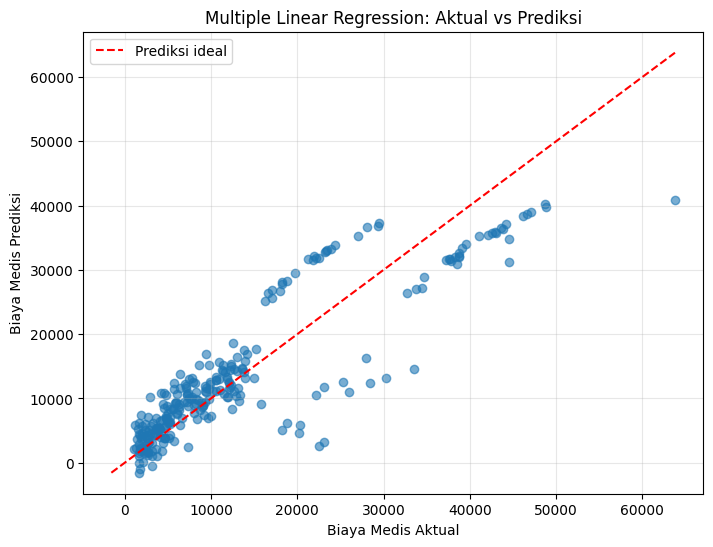

In [6]:
# Grafik nilai aktual vs nilai prediksi
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Garis prediksi ideal
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--",
    label="Prediksi ideal"
)

plt.xlabel("Biaya Medis Aktual")
plt.ylabel("Biaya Medis Prediksi")
plt.title("Multiple Linear Regression: Aktual vs Prediksi")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Jika titik-titik mendekati garis merah, prediksi cenderung mendekati biaya aktual. Titik yang jauh dari garis menunjukkan prediksi dengan kesalahan lebih besar.

7. Analisis dan kesimpulan

In [7]:
# Ringkasan analisis berdasarkan hasil evaluasi
print("=== ANALISIS HASIL ===")

print(f"Nilai R-squared: {r2:.4f}")

if r2 >= 0.75:
    print("Model menjelaskan variasi biaya medis dengan cukup baik.")
elif r2 >= 0.50:
    print("Model menjelaskan sebagian variasi biaya medis, tetapi masih memiliki keterbatasan.")
else:
    print("Kemampuan model menjelaskan variasi biaya medis masih terbatas.")

print(f"Rata-rata kesalahan absolut (MAE): {mae:.2f}")
print(f"Rata-rata kesalahan kuadrat (MSE): {mse:.2f}")

print("\nContoh perbandingan hasil prediksi:")
hasil_prediksi = pd.DataFrame({
    "Biaya Aktual": y_test.iloc[:10].values,
    "Biaya Prediksi": y_pred[:10]
})

display(hasil_prediksi.round(2))

=== ANALISIS HASIL ===
Nilai R-squared: 0.7836
Model menjelaskan variasi biaya medis dengan cukup baik.
Rata-rata kesalahan absolut (MAE): 4181.19
Rata-rata kesalahan kuadrat (MSE): 33596915.85

Contoh perbandingan hasil prediksi:


,Biaya Aktual,Biaya Prediksi
0,9095.07,8969.55
1,5272.18,7068.75
2,29330.98,36858.41
3,9301.89,9454.68
4,33750.29,26973.17
5,4536.26,10864.11
6,2117.34,170.28
7,14210.54,16903.45
8,3732.63,1092.43
9,10264.44,11218.34


## Analisis
Berdasarkan hasil pengujian, model Multiple Linear Regression memperoleh nilai R-squared sebesar 0,7836, yang berarti model dapat menjelaskan sekitar 78,36% variasi biaya medis personal pada data uji. Sementara itu, nilai MAE sebesar 4.181,19 menunjukkan bahwa rata-rata selisih absolut antara biaya medis aktual dan prediksi sekitar 4.181,19 satuan biaya. Nilai MSE sebesar 33.596.915,85 menunjukkan rata-rata kuadrat kesalahan prediksi. Pada tabel perbandingan, beberapa prediksi mendekati nilai aktual, misalnya biaya aktual 9.301,89 diprediksi sebesar 9.454,68. Namun, terdapat juga perbedaan yang cukup besar, seperti biaya aktual 4.536,26 yang diprediksi sebesar 10.864,11. Hal ini menunjukkan bahwa model sudah mampu menjelaskan sebagian besar variasi biaya medis, tetapi hasil prediksinya belum selalu akurat untuk setiap individu.

## Kesimpulan
> Berdasarkan praktikum yang telah dilakukan, Multiple Linear Regression dapat digunakan untuk memprediksi biaya medis personal berdasarkan usia, jenis kelamin, BMI, jumlah anak, status merokok, dan wilayah tempat tinggal. Nilai R-squared sebesar 0,7836 menunjukkan bahwa model memiliki kemampuan prediksi yang cukup baik pada data uji. Meskipun demikian, kesalahan prediksi masih ditemukan pada beberapa data. Oleh karena itu, model masih dapat dikembangkan lebih lanjut agar hasil prediksi biaya medis menjadi lebih akurat.